In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    normalized_mutual_info_score, adjusted_mutual_info_score,
    adjusted_rand_score, fowlkes_mallows_score,
)

dataset = "HLN_A1"
base_dir = Path(f"../results/ablation/{dataset}")
metrics = ["NMI", "Acc", "ARI", "FMI", "AMI"]
files = {
    "SpaGenFuse": "our_repeat/adata_repeat.h5ad",
    "w/o consistency": "adata_repeat_wo_consistency.h5ad",
    "w/o sVAE": "adata_repeat_wo_sVAE.h5ad",
    "w/o spectral": "adata_repeat_wo_spectral.h5ad",
    "w/o PoE": "adata_repeat_wo_POE.h5ad",
    "w/o adversarial": "adata_repeat_wo_adversarial.h5ad",
    "GCN": "adata_repeat_gcn.h5ad",
    "POS": "adata_repeat_pos_spec.h5ad",
    "Concatenation": "adata_repeat_wo_POE.h5ad",
    "Weighted Average": "adata_repeat_weighted_avg.h5ad",
    "Attention": "adata_repeat_attention.h5ad",
    "Posterior Mean": "adata_repeat_post_mean.h5ad",
}
ablation_methods = list(files)[:6]


def clustering_accuracy(y_true, y_pred):
    size = max(y_true.max(), y_pred.max()) + 1
    counts = np.zeros((size, size), dtype=int)
    np.add.at(counts, (y_pred, y_true), 1)
    rows, cols = linear_sum_assignment(-counts)
    return counts[rows, cols].sum() / len(y_true)


cached_metrics = {}
for filename in dict.fromkeys(files.values()):
    obs = ad.read_h5ad(base_dir / filename).obs
    obs = obs.loc[obs["manual-anno"].notna()]
    y_true = obs["manual-anno"].astype("category").cat.codes.to_numpy()
    rows = []
    for seed in range(5):
        y_pred = obs[f"X_our_rep{seed}_cluster"].astype("category").cat.codes.to_numpy()
        rows.append([
            normalized_mutual_info_score(y_true, y_pred, average_method="geometric"),
            clustering_accuracy(y_true, y_pred),
            adjusted_rand_score(y_true, y_pred),
            fowlkes_mallows_score(y_true, y_pred),
            adjusted_mutual_info_score(y_true, y_pred),
        ])
    cached_metrics[filename] = pd.DataFrame(rows, columns=metrics).assign(Seed=range(5))

df = pd.concat([cached_metrics[path].assign(Method=name) for name, path in files.items()], ignore_index=True)
means = df.groupby("Method")[metrics].mean()
stds = df.groupby("Method")[metrics].std()
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "pdf.fonttype": 42})


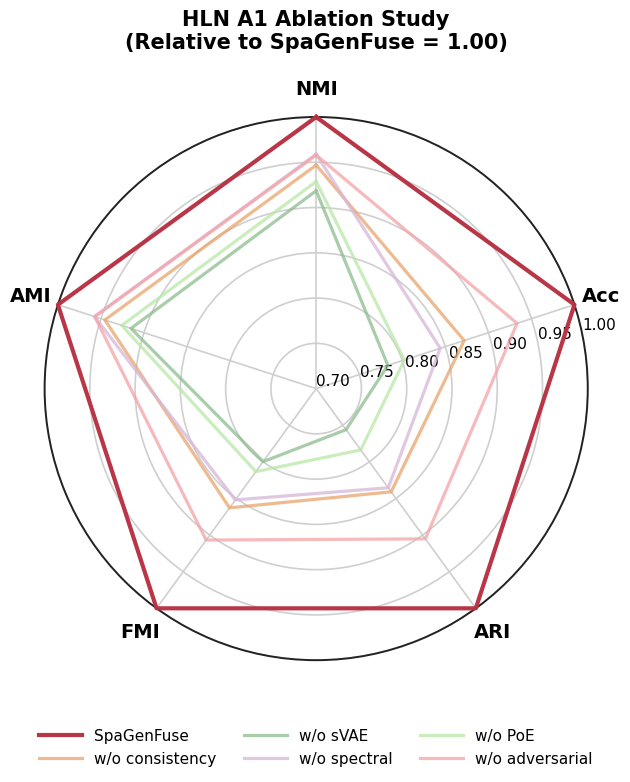

In [4]:
baseline = means.loc["SpaGenFuse", metrics]
if not np.isfinite(baseline).all() or (baseline <= 0).any():
    raise ValueError("SpaGenFuse baseline scores must be finite and positive.")
normalized = means.loc[ablation_methods, metrics].div(baseline)
values = normalized.to_numpy()
if not np.isfinite(values).all() or values.min() < 0.70 - 1e-8 or values.max() > 1.00 + 1e-8:
    raise ValueError("Normalized radar scores must lie between 0.70 and 1.00.")

angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False)
closed_angles = np.append(angles, angles[0])
colors = ["#B83243", "#E9A36A", "#8DBB8E", "#D7B6D8", "#B9E7A7", "#F4A3A6"]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
for method, color in zip(ablation_methods, colors):
    values = normalized.loc[method].to_numpy()
    full_model = method == "SpaGenFuse"
    ax.plot(closed_angles, np.append(values, values[0]), label=method, color=color,
            linewidth=3.0 if full_model else 2.3, alpha=0.98 if full_model else 0.75,
            zorder=5 if full_model else 3, clip_on=not full_model)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles)
ax.set_xticklabels(metrics, fontsize=14, fontweight="bold")
ax.set_ylim(0.70, 1.00)
yticks = np.arange(0.70, 1.001, 0.05)
ax.set_yticks(yticks)
ax.set_yticklabels([f"{v:.2f}" for v in yticks], fontsize=11)
ax.set_rlabel_position(78)
ax.grid(color="#CFCFCF", linewidth=1.2)
ax.spines["polar"].set_color("#222222")
ax.spines["polar"].set_linewidth(1.4)
ax.tick_params(axis="x", pad=10)
ax.set_title(f"{dataset.replace('_', ' ')} Ablation Study\n(Relative to SpaGenFuse = 1.00)",
             fontsize=15, fontweight="bold", pad=22)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=False,
          fontsize=11, handlelength=2.8, columnspacing=1.8)
plt.tight_layout()
plt.show()


In [5]:
fusion_colors = {
    "SpaGenFuse": "#4C78A8", "GCN": "#F58518", "POS": "#9D755D",
    "Concatenation": "#54A24B", "Weighted Average": "#E45756",
    "Attention": "#72B7B2", "Posterior Mean": "#B279A2",
}


def plot_bars(methods, title, width):
    x = np.arange(len(metrics))
    fig, ax = plt.subplots(figsize=(13, 5.2))
    for i, method in enumerate(methods):
        positions = x + (i - (len(methods) - 1) / 2) * width
        ax.bar(positions, means.loc[method, metrics], width=width,
               yerr=stds.loc[method, metrics], capsize=3, label=method,
               color=fusion_colors[method], edgecolor="none", linewidth=0)
        runs = df.loc[df["Method"] == method].sort_values("Seed")
        offsets = np.linspace(-0.25, 0.25, len(runs)) * width
        for j, metric in enumerate(metrics):
            ax.scatter(positions[j] + offsets, runs[metric], s=5, color="black",
                       linewidths=0, zorder=4, label="_nolegend_")
    observed = df.loc[df["Method"].isin(methods), metrics].to_numpy()
    mean_values, std_values = means.loc[methods, metrics].to_numpy(), stds.loc[methods, metrics].to_numpy()
    lower = min(observed.min(), (mean_values - std_values).min())
    upper = max(observed.max(), (mean_values + std_values).max())
    ax.set_ylim(min(0.0, lower - 0.02), upper + 0.06)
    ax.set_ylabel("Score")
    ax.set_title(f"{dataset.replace('_', ' ')} {title}")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=25, ha="right")
    ax.legend(frameon=False, ncol=min(3, len(methods)))
    ax.grid(False)
    plt.tight_layout()
    plt.show()


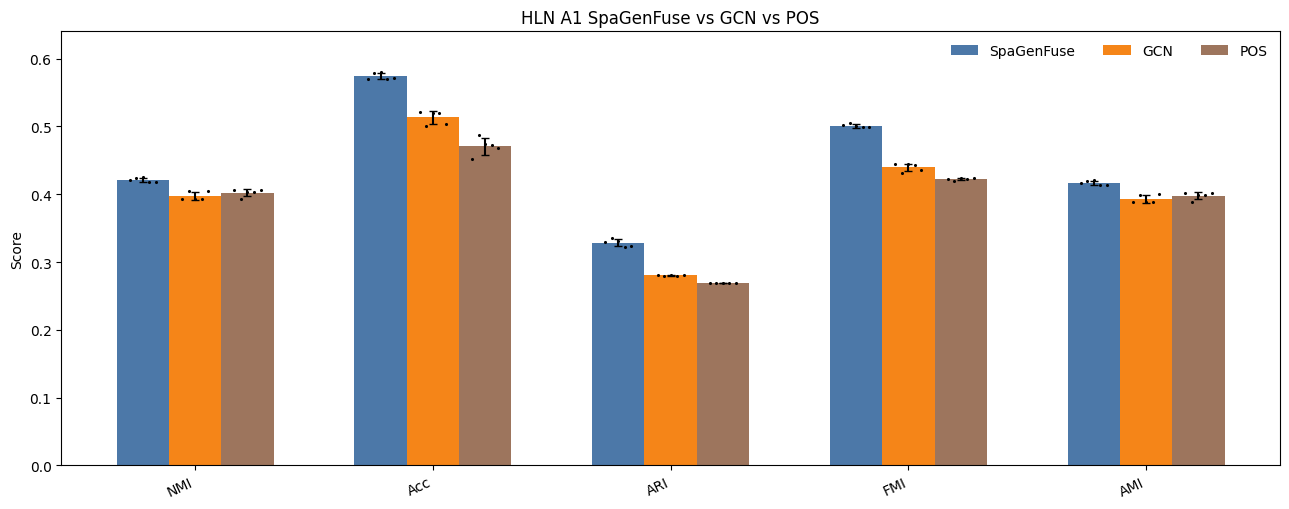

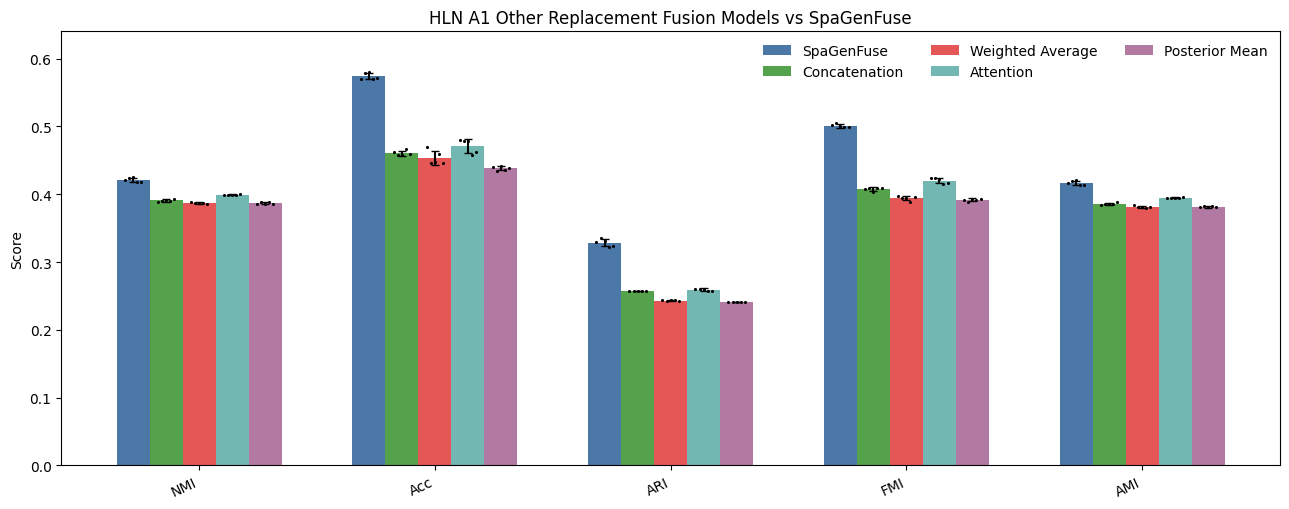

In [6]:
plot_bars(["SpaGenFuse", "GCN", "POS"], "SpaGenFuse vs GCN vs POS", width=0.22)
plot_bars(["SpaGenFuse", "Concatenation", "Weighted Average", "Attention", "Posterior Mean"],
          "Other Replacement Fusion Models vs SpaGenFuse", width=0.14)
